In [168]:
#NECESSARY IMPORTS

import pandas as pd #PANDAS
import matplotlib.pyplot as plt #PLOTTING
import statistics
import numpy as np
import sys #GETTING EQUATIONS
sys.path.append('../bgc-analysis')
from  calc_sensor import pH_sbe, o2_sbe, mcoms
from datetime import datetime
from db_api import get_continuous_one_profile,get_continuous_one_float
from calc_sensor import pH_sbe
sys.path.clear
sys.path.append('C:\\Users\\aidan.thayer\Documents\\repositories\\test-analysis\\')
from get_cal_sn import get_cal


In [169]:
#UPDATE FOR EACH FLOAT
SN =  1557
n=300
outfile = 'G://Shared drives/WHOI Argo/BGC/Float Tracking/pressure_test_results/' + 'combined_test_results' + '/' + str(SN) + '_calcs_' + ".xlsx"

In [170]:
data = pd.read_excel(outfile)

In [171]:
sal = data['PSAL']

msal = statistics.mean(sal[14:])

saldiff= sal-msal
timediff = []



In [172]:
timediff = []

for i, timedif in enumerate(data['DATE'][:-1]):
    timediff.append(np.timedelta64(data['DATE'][i+1]-data['DATE'][i], 's'))
display(timediff)
td = np.array(timediff).cumsum() # time after starttime
starttime = data['DATE'][0]
td = td.astype(float)

[numpy.timedelta64(91,'s'),
 numpy.timedelta64(54,'s'),
 numpy.timedelta64(54,'s'),
 numpy.timedelta64(54,'s'),
 numpy.timedelta64(54,'s'),
 numpy.timedelta64(54,'s'),
 numpy.timedelta64(54,'s'),
 numpy.timedelta64(54,'s'),
 numpy.timedelta64(54,'s'),
 numpy.timedelta64(54,'s'),
 numpy.timedelta64(54,'s'),
 numpy.timedelta64(54,'s'),
 numpy.timedelta64(54,'s'),
 numpy.timedelta64(54,'s'),
 numpy.timedelta64(54,'s'),
 numpy.timedelta64(54,'s'),
 numpy.timedelta64(54,'s'),
 numpy.timedelta64(54,'s'),
 numpy.timedelta64(54,'s'),
 numpy.timedelta64(54,'s'),
 numpy.timedelta64(54,'s'),
 numpy.timedelta64(54,'s'),
 numpy.timedelta64(54,'s'),
 numpy.timedelta64(54,'s'),
 numpy.timedelta64(54,'s'),
 numpy.timedelta64(54,'s'),
 numpy.timedelta64(54,'s'),
 numpy.timedelta64(54,'s'),
 numpy.timedelta64(54,'s'),
 numpy.timedelta64(54,'s'),
 numpy.timedelta64(54,'s'),
 numpy.timedelta64(54,'s'),
 numpy.timedelta64(54,'s'),
 numpy.timedelta64(91,'s'),
 numpy.timedelta64(54,'s'),
 numpy.timedelta64(5

In [173]:
print(len(td))

1565


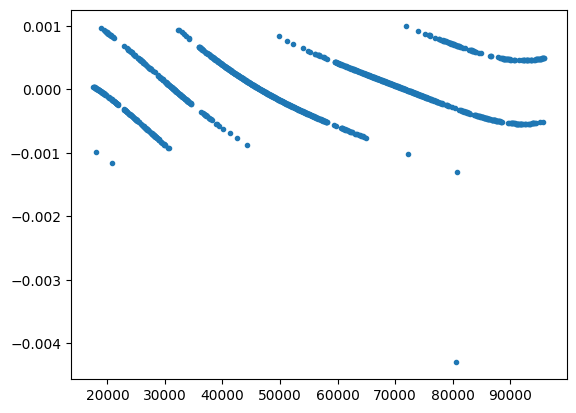

In [174]:
fit1, fit2, fit3, fit4, fit5, fit6 = np.polyfit(td[n:], sal[n:-1], 5)


sals = []
for t in td:
    sals.append(((fit1*t**5)+ (fit2*t**4)+(fit3*t**3)+(fit4*t**2)+(fit5*t)+fit6))


psal = sal[:-1]-sals

plt.scatter(td[n:],psal[n:], marker = '.')

Text(0.5, 0.98, 'Salinity Check')

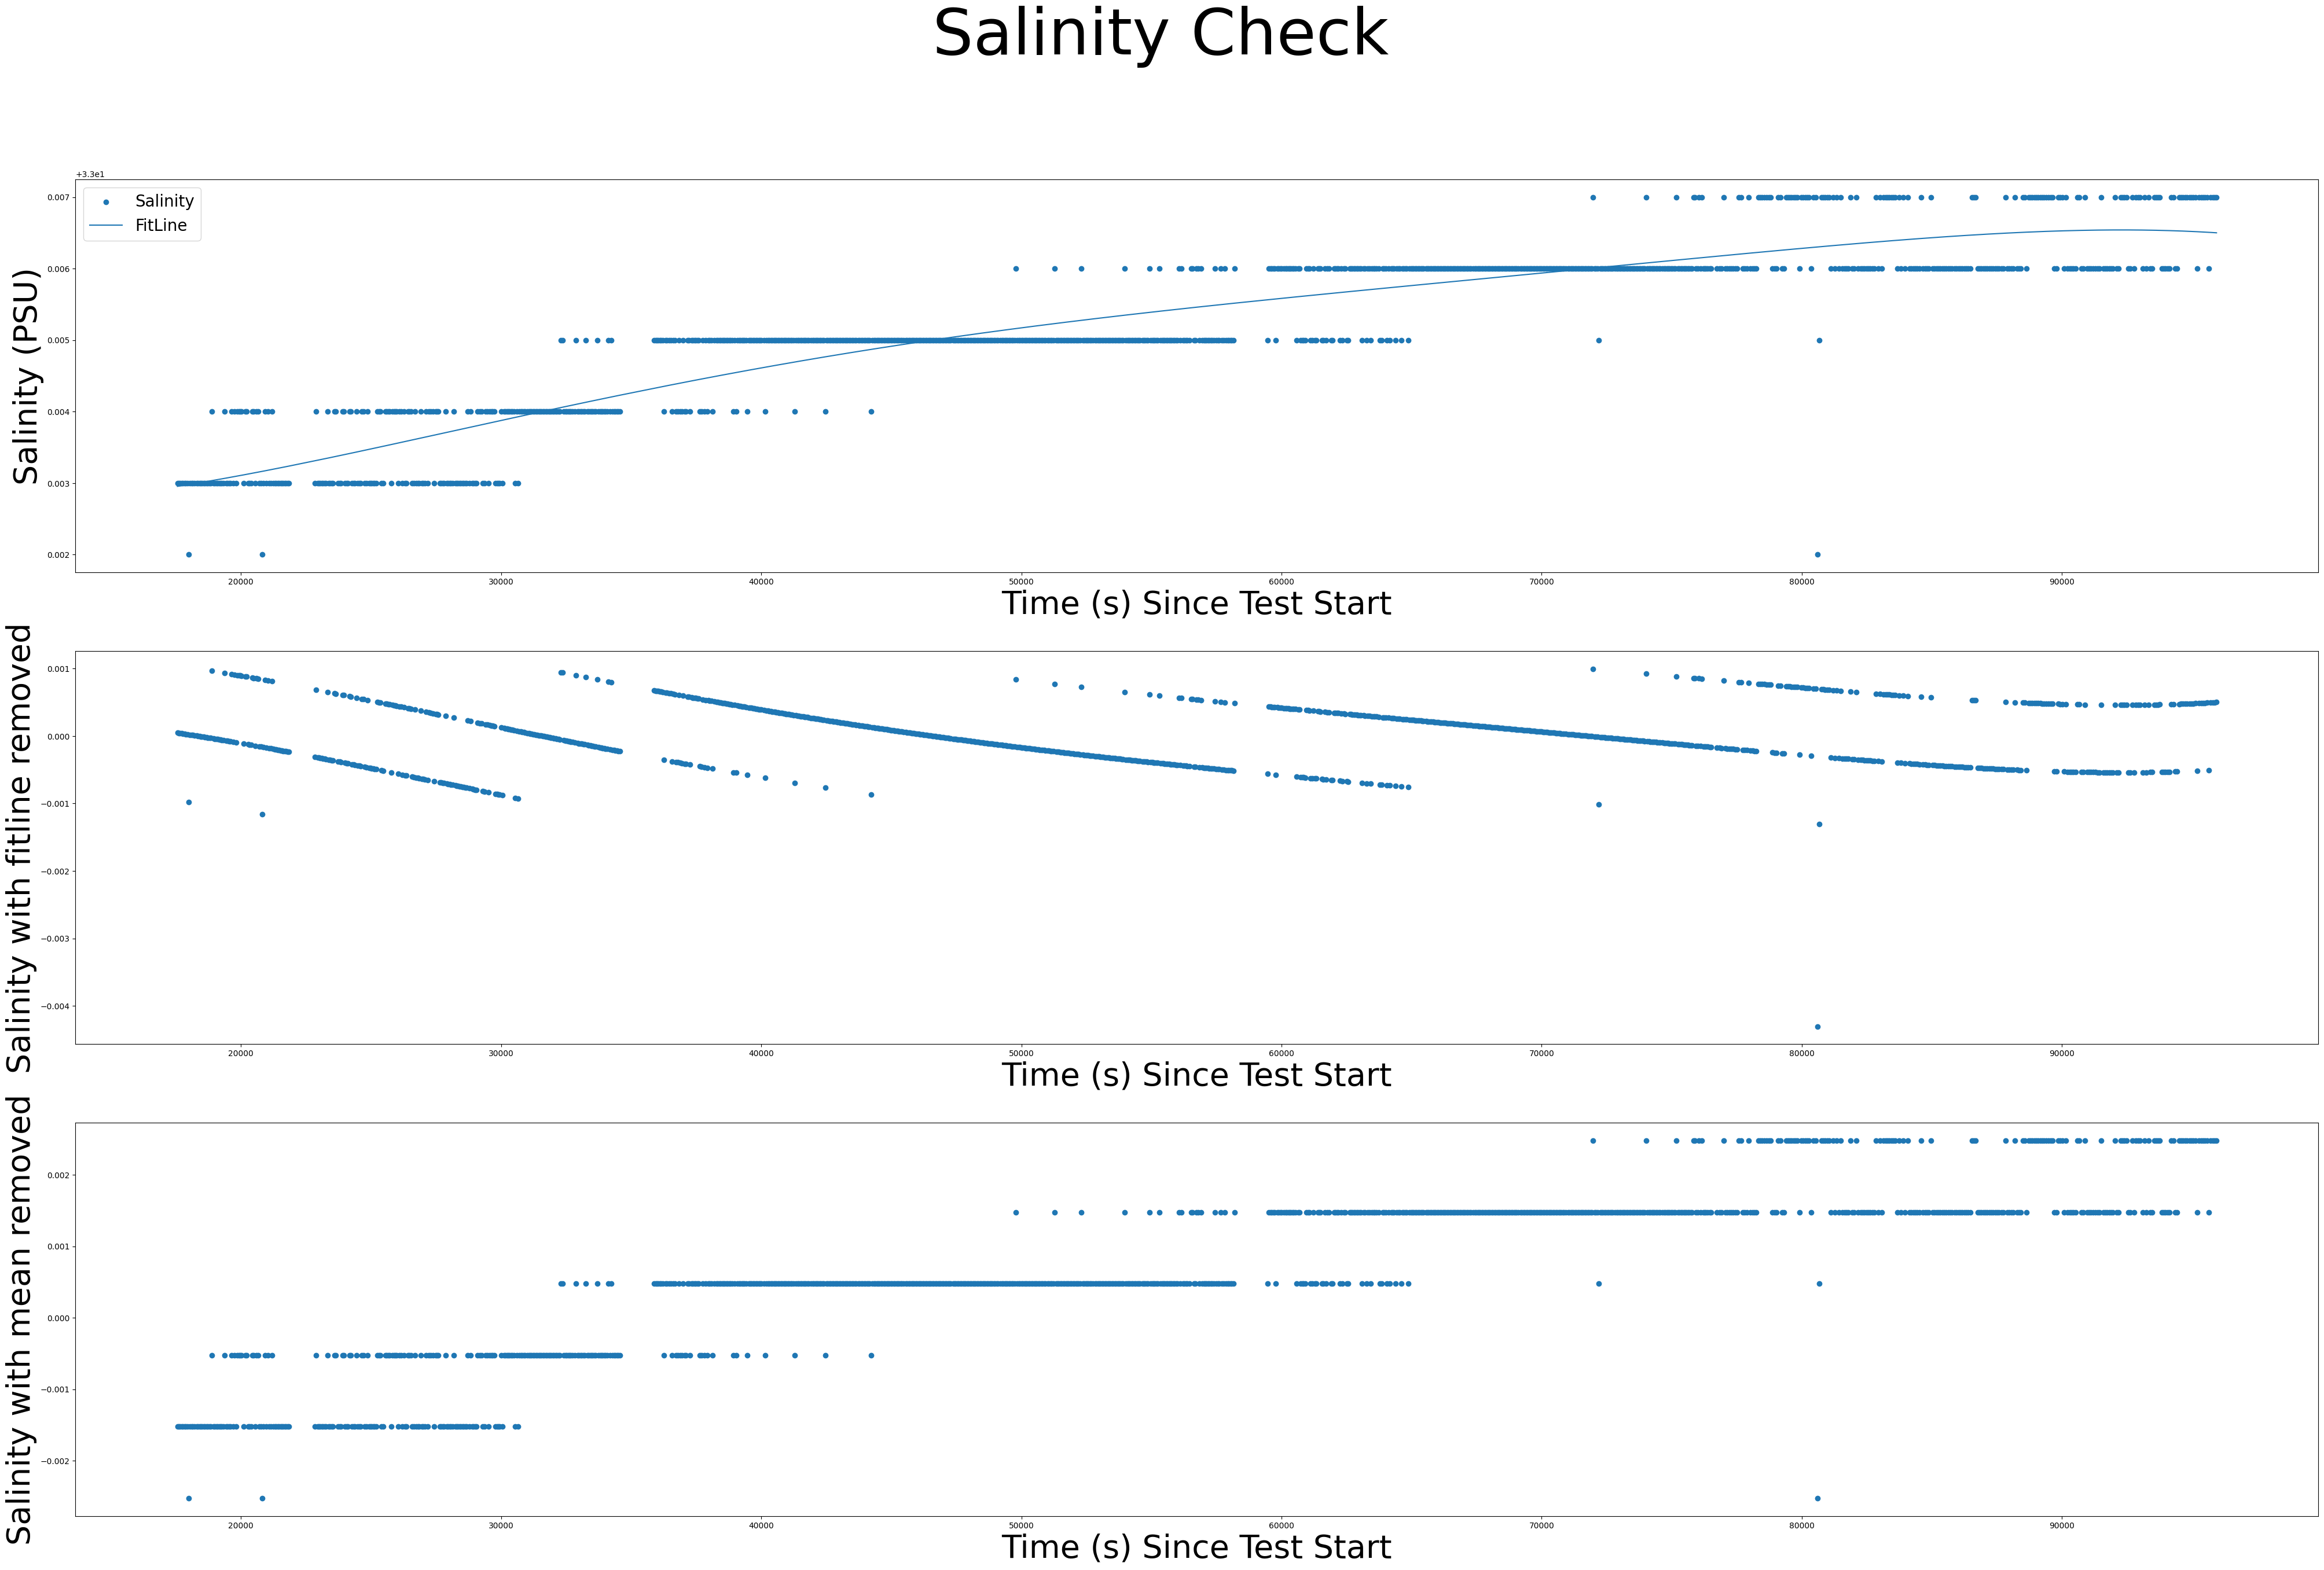

In [175]:
fig, fig0=plt.subplots(3,1,figsize = (50,30))
fig0[0].scatter(td[n:],sal[n:-1])
fig0[0].plot(td[n:],sals[n:])
fig0[1].scatter(td[n:],psal[n:])
fig0[1].set_xlabel('Time (s) Since Test Start', fontsize = 40)
fig0[0].set_ylabel('Salinity (PSU)', fontsize = 40)
fig0[1].set_ylabel('Salinity with fitline removed', fontsize = 40)
fig0[0].legend(['Salinity', 'FitLine'],fontsize = '20')
fig0[2].scatter(td[n:], saldiff[n:-1])
fig0[0].set_xlabel('Time (s) Since Test Start', fontsize = 40)
fig0[2].set_xlabel('Time (s) Since Test Start', fontsize = 40)
fig0[2].set_ylabel('Salinity with mean removed', fontsize = 40)
fig.suptitle('Salinity Check', fontsize= 80)

